# Ideas

1. **Image Preprocessing**
    -   **Dataset Augmentation**
        *   x10 the training dataset
    -   Grayscaling
        *   Primarily reduce the computational power
2. **Intuitively Group Age Classes**
    -   Roblox: 5-8, 9-12, 13-15, 16-17, 18-20, and 21+
    -   Business-wise, we have to add more label for 21+
    -   Suggestion for 21+ group: 21-27, 28-45, 46-65, 66+
        -   21-27 years: Categorized as mature adults.
        -   28-45 years: Representing the adult stage of life.
        -   46-65 years: Distinguished by the appearance of more pronounced aging features.
        -   66+ years: Represented by features like graying hair and aging skin.
3. Use CNN-Based Deep Learning Aproach


Proposed labels: 1-4, 5-8, 9-12, 13-15, 16-17, 18-20, 21-27, 28-45, 46-65, 66+

# Import Libraries and Setup Environments

In [1]:
# Standard libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

# For CNN
from keras.preprocessing.image import load_img
from keras import mixed_precision
from keras.models import Sequential, Model
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, concatenate
from keras.optimizers import SGD, Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.applications import MobileNetV2, ResNet50, VGG16, MobileNetV2, DenseNet121

# Aid releasing VRAM
from keras import backend as K
import gc

# For loading and preprocessing dataset(s) and others
import os
#import cv2
import glob
#import imagehash
#from tqdm.notebook import tqdm
#from PIL import Image

I0000 00:00:1793032471.670606   99991 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793032472.047412   99991 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793032473.291274   99991 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import kagglehub

#facial_age_path = kagglehub.dataset_download("frabbisw/facial-age", output_dir="/home/sisi/projects/age-estimation/data/raw/facial-age-ver1")
#utk_path = kagglehub.dataset_download("jangedoo/utkface-new", output_dir="/home/sisi/projects/age-estimation/data/raw/UTKFace", force_download=True)

utk_path = "/home/sisi/projects/age-estimation/data/raw/UTKFace"
facial_age_path = "/home/sisi/projects/age-estimation/data/raw/facial-age-ver1"

print(facial_age_path)
print(utk_path)

/home/sisi/projects/age-estimation/data/raw/facial-age-ver1
/home/sisi/projects/age-estimation/data/raw/UTKFace


In [3]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# This will reduce the VRAM consumed
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU Memory Growth Enabled!")

GPU Memory Growth Enabled!


In [5]:
mixed_precision.set_global_policy("mixed_float16")

# Load the Dataset

## UTKFace


In [6]:
# The UTKFace dataset filenames are formatted as [age]_[gender]_[race]_[date&time].jpg
utk_image_paths:list = glob.glob(os.path.join(utk_path, 'UTKFace', '*.jpg'))
# if not image_paths:
#     image_paths = glob.glob(os.path.join(utk_path, '*/*.jpg')) + glob.glob(os.path.join(utk_path, '*.jpg'))

#print((image_paths[0:9]))
print(f"Total images found: {len(utk_image_paths)}")

# Create a DataFrame
data = []
for path in utk_image_paths:
    filename = os.path.basename(path)
    parts = filename.split('_')
    if len(parts) >= 3:
        try:
            age = int(parts[0])
            data.append({'path': path, 'age': age})
        except ValueError:
            continue

df_utk = pd.DataFrame(data)
display(df_utk.head())

Total images found: 23708


,path,age
0,/home/sisi/projects/age-estimation/data/raw/UT...,39
1,/home/sisi/projects/age-estimation/data/raw/UT...,23
2,/home/sisi/projects/age-estimation/data/raw/UT...,26
3,/home/sisi/projects/age-estimation/data/raw/UT...,31
4,/home/sisi/projects/age-estimation/data/raw/UT...,42


## facial age (version 1)

In [7]:
# The facial-age dataset contains of sub-folders in /facial-age-ver1/face-age/ and /facial-age-ver1/face_age/face_age/. Both will lead to multiple sub-folders named after an integer, in which contains the .png files

f_a_image_paths = glob.glob(os.path.join(facial_age_path, 'face_age/face_age', '*/*.png')) # We will just get the folders here


# Create a DataFrame
f_a_data = []
for path in f_a_image_paths:
    parts = path.split('/')
    try:
        age = int(parts[-2])
        f_a_data.append({'path': path, 'age': age})
    except:
        continue

print(f"Total images found: {len(f_a_image_paths)}")

df_f_a = pd.DataFrame(f_a_data)
display(df_f_a.head())

Total images found: 9778


,path,age
0,/home/sisi/projects/age-estimation/data/raw/fa...,46
1,/home/sisi/projects/age-estimation/data/raw/fa...,46
2,/home/sisi/projects/age-estimation/data/raw/fa...,46
3,/home/sisi/projects/age-estimation/data/raw/fa...,46
4,/home/sisi/projects/age-estimation/data/raw/fa...,46


## Combine 2 datasets


In [8]:
df = pd.concat([df_f_a, df_utk], ignore_index=True)
print(df.shape)

(33486, 2)


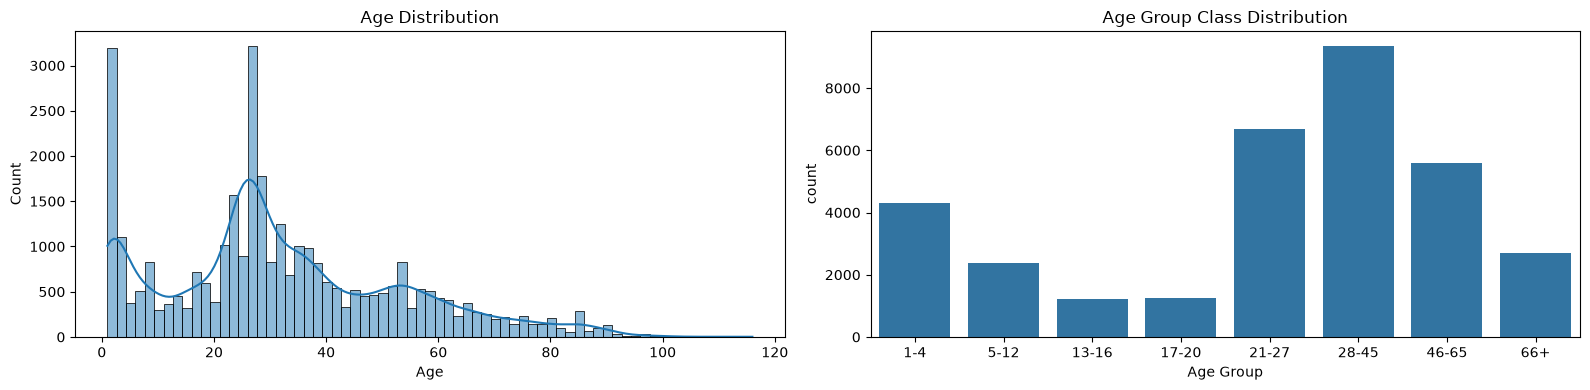

In [9]:
def map_age_to_class(age):
    if age <= 4:    return 0    # 1-4
    elif age <= 12: return 1    # 5-12
    elif age <= 16: return 2    # 13-16
    elif age <= 20: return 3    # 17-20
    elif age <= 27: return 4    # 21-27
    elif age <= 45: return 5    # 28-45
    elif age <= 65: return 6    # 46-65
    else: return 7              # 66+

df['label'] = df['age'].apply(map_age_to_class)

class_names = ['1-4', '5-12', '13-16', '17-20', '21-27', '28-45', '46-65', '66+']
num_classes = len(class_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(data=df, x='age', kde=True, ax=ax1)
ax1.set_title('Age Distribution')
ax1.set_xlabel('Age')

sns.countplot(x='label', data=df, ax=ax2)
ax2.set_xticks(range(len(class_names)), labels=class_names)
ax2.set_title('Age Group Class Distribution')
ax2.set_xlabel('Age Group')

plt.tight_layout()
plt.show()


# Train-Test Split & tf.data Pipeline with Augmentation

In [10]:
from sklearn.model_selection import train_test_split

# Train/Val/Test split (80/10/10)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

IMG_SIZE = 128
BATCH_SIZE = 128
EPOCHS = 100  # Can be increased for better convergence

def parse_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(1/18),
    tf.keras.layers.RandomZoom(0.1),
])

train_ds = tf.data.Dataset.from_tensor_slices((train_df['path'].values, train_df['label'].values))
train_ds = train_ds.shuffle(len(train_df)).map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df['path'].values, val_df['label'].values))
val_ds = val_ds.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1793032475.531552   99991 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13549 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


# Model 1: Simple CNN Architecture

In [33]:
simple_model = Sequential(
    [
        Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        Conv2D(16, (7, 7), activation='silu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(32, (5, 5), activation='silu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='silu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='silu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(256, (3, 3), activation='silu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        GlobalAveragePooling2D(),
        Dense(256, activation='silu'),
        BatchNormalization(),
        Dropout(0.25),
        Dense(128, activation='silu'),
        Dropout(0.25),
        Dense(8, activation='softmax')
    ],
    name="SimpleCNN"
)

simple_model.summary()

Model: "SimpleCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_108 (Conv2D)             │ (None, 128, 128, 16)   │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_52          │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 64, 64, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_53          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_110 (Conv2D)             │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_111 (Conv2D)             │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_112 (Conv2D)             │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 505,448 (1.93 MB)

 Trainable params: 503,944 (1.92 MB)

 Non-trainable params: 1,504 (5.88 KB)

In [12]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=3, min_lr=1e-8, verbose=1)

In [34]:
simple_model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Training Simple CNN...")
history_simple = simple_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Simple CNN...
Epoch 1/100


I0000 00:00:1793038942.090544  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_527894__.137


208/210 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3942 - loss: 1.6237

I0000 00:00:1793038961.837418  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_527894__.137


210/210 ━━━━━━━━━━━━━━━━━━━━ 34s 105ms/step - accuracy: 0.3946 - loss: 1.6219 - val_accuracy: 0.2699 - val_loss: 1.9028 - learning_rate: 0.0010
Epoch 2/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.5177 - loss: 1.1869 - val_accuracy: 0.2822 - val_loss: 2.1732 - learning_rate: 0.0010
Epoch 3/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.5666 - loss: 1.0617 - val_accuracy: 0.5058 - val_loss: 1.2217 - learning_rate: 0.0010
Epoch 4/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.5916 - loss: 0.9917 - val_accuracy: 0.5838 - val_loss: 0.9841 - learning_rate: 0.0010
Epoch 5/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.6070 - loss: 0.9461 - val_accuracy: 0.5802 - val_loss: 1.0197 - learning_rate: 0.0010
Epoch 6/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.6243 - loss: 0.9059 - val_accuracy: 0.5300 - val_loss: 1.1374 - learning_rate: 0.0010
Epoch 7/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.6373 - loss: 0

# Model 2: Complex CNN Architecture (VGG block style)

In [30]:
def build_complex_cnn():
    # Implementing a scratch VGG-style deep block structure
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Block 1 (VGG Block)
    x = Conv2D(64, (3, 3), activation='silu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)

    # Block 2 (VGG Block)
    x = Conv2D(128, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)

    # Block 3 (VGG Block)
    x = Conv2D(256, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)

    # Block 4 (VGG Block)
    x = Conv2D(512, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)

    # Block 5 (VGG Block)
    x = Conv2D(512, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, (3, 3), activation='silu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)

    # Fully Connected layers
    x = GlobalAveragePooling2D()(x)
    x = Dense(2048, activation='silu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(1024, activation='silu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    outputs = Dense(8, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name='VGG_Scratch_ComplexCNN')
    return model

complex_model = build_complex_cnn()
complex_model.summary()

Model: "VGG_Scratch_ComplexCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_100 (Conv2D)             │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_101 (Conv2D)             │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_41 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_102 (Conv2D)             │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_103 (Conv2D)             │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_42 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_104 (Conv2D)             │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_105 (Conv2D)             │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_43 (MaxPooling2D) │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_106 (Conv2D)             │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_107 (Conv2D)             │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │             

 Total params: 12,400,776 (47.31 MB)

 Trainable params: 12,389,128 (47.26 MB)

 Non-trainable params: 11,648 (45.50 KB)

In [31]:
complex_model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Training Complex CNN...")
history_complex = complex_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Training Complex CNN...
Epoch 1/100


I0000 00:00:1793038460.197239  110552 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_489004__.181


208/210 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3049 - loss: 2.2378

I0000 00:00:1793038481.452091  110553 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_489004__.181


210/210 ━━━━━━━━━━━━━━━━━━━━ 38s 119ms/step - accuracy: 0.3055 - loss: 2.2344 - val_accuracy: 0.2765 - val_loss: 2.5723 - learning_rate: 0.0010
Epoch 2/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.4446 - loss: 1.4695 - val_accuracy: 0.0893 - val_loss: 6.8017 - learning_rate: 0.0010
Epoch 3/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - accuracy: 0.5048 - loss: 1.2809 - val_accuracy: 0.3846 - val_loss: 1.6435 - learning_rate: 0.0010
Epoch 4/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.5257 - loss: 1.2181 - val_accuracy: 0.3789 - val_loss: 1.7397 - learning_rate: 0.0010
Epoch 5/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.5455 - loss: 1.1605 - val_accuracy: 0.1248 - val_loss: 3.7332 - learning_rate: 0.0010
Epoch 6/100
209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5717 - loss: 1.0680
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
210/210 ━━━━━━━━━━━━━━━━━━━━ 14s 63ms/step - accuracy: 0.5717 - loss: 1.

# Model 3: Transfer Learning (MobileNetV2 Fine-tuning)

In [16]:
def build_transfer_learning_model():
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    base_model.trainable = False  # Freeze base model layers initially

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    # Scale inputs between [-1, 1] as expected by MobileNetV2
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)

    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(512)(x)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)

    outputs = Dense(8, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name="Transfer_FineTuned_CNN")
    return model, base_model

transfer_model, base_model = build_transfer_learning_model()
transfer_model.summary()

Model: "Transfer_FineTuned_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,920,008 (11.14 MB)

 Trainable params: 661,000 (2.52 MB)

 Non-trainable params: 2,259,008 (8.62 MB)

In [17]:
transfer_model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Training Transfer Learning Model...")
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Transfer Learning Model...
Epoch 1/100


I0000 00:00:1793033522.015788  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_109634__.137


209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4286 - loss: 1.6449

I0000 00:00:1793033540.440396  110552 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_109634__.137


210/210 ━━━━━━━━━━━━━━━━━━━━ 35s 111ms/step - accuracy: 0.4286 - loss: 1.6446 - val_accuracy: 0.4816 - val_loss: 1.4169 - learning_rate: 1.0000e-04
Epoch 2/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.4987 - loss: 1.3553 - val_accuracy: 0.4903 - val_loss: 1.3390 - learning_rate: 1.0000e-04
Epoch 3/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.5125 - loss: 1.2860 - val_accuracy: 0.4742 - val_loss: 1.3513 - learning_rate: 1.0000e-04
Epoch 4/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.5277 - loss: 1.2377 - val_accuracy: 0.5267 - val_loss: 1.2377 - learning_rate: 1.0000e-04
Epoch 5/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.5313 - loss: 1.2153 - val_accuracy: 0.5297 - val_loss: 1.1910 - learning_rate: 1.0000e-04
Epoch 6/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.5380 - loss: 1.1862 - val_accuracy: 0.5327 - val_loss: 1.1807 - learning_rate: 1.0000e-04
Epoch 7/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - acc

In [18]:
print("Unfreezing MobileNetV2 base model layers for fine-tuning...")
base_model.trainable = True

# Freeze all layers up to layer 100
for layer in base_model.layers[:100]:
    layer.trainable = False

transfer_model.summary()

Unfreezing MobileNetV2 base model layers for fine-tuning...


Model: "Transfer_FineTuned_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,242,014 (16.18 MB)

 Trainable params: 2,522,440 (9.62 MB)

 Non-trainable params: 397,568 (1.52 MB)

 Optimizer params: 1,322,006 (5.04 MB)

In [19]:
# Re-compile with a very small learning rate for fine-tuning
transfer_model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy']
)

print("Fine-tuning MobileNetV2 model...")
history_transfer_finetune = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,  # Fine-tuning usually requires fewer epochs
    callbacks=[early_stopping, reduce_lr],
    shuffle=True,
	verbose=1
)

Fine-tuning MobileNetV2 model...
Epoch 1/100


I0000 00:00:1793033747.597293  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_153586__.263


208/210 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5179 - loss: 1.3079

I0000 00:00:1793033772.330674  110555 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_153586__.263


210/210 ━━━━━━━━━━━━━━━━━━━━ 54s 142ms/step - accuracy: 0.5183 - loss: 1.3062 - val_accuracy: 0.5118 - val_loss: 1.4781 - learning_rate: 1.0000e-04
Epoch 2/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.6109 - loss: 0.9646 - val_accuracy: 0.5279 - val_loss: 1.3114 - learning_rate: 1.0000e-04
Epoch 3/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.6494 - loss: 0.8498 - val_accuracy: 0.5533 - val_loss: 1.1413 - learning_rate: 1.0000e-04
Epoch 4/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.6854 - loss: 0.7720 - val_accuracy: 0.5715 - val_loss: 1.0724 - learning_rate: 1.0000e-04
Epoch 5/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.7148 - loss: 0.7034 - val_accuracy: 0.5906 - val_loss: 1.0044 - learning_rate: 1.0000e-04
Epoch 6/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.7362 - loss: 0.6482 - val_accuracy: 0.6229 - val_loss: 0.9548 - learning_rate: 1.0000e-04
Epoch 7/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - ac

# Model 4: The Ultimate Model
The input is divided into branches, each is applied with a modern CNN model, then GlobalAveragePooling, and finally, all branches are concatenated into one Fully Connected layer

In [20]:
def inception_block(input, filters_1x1, filters_3x3_tuple: tuple, filters_5x5_tuple: tuple, filters_pool_proj):
    # Branch A: 1x1 Conv
    branch1 = Conv2D(filters_1x1, (1, 1), padding='same', activation='silu')(input)

    # Branch B: 1x1 Conv -> 3x3 Conv
    filters_3x3_reduce, filters_3x3 = filters_3x3_tuple
    branch2 = Conv2D(filters_3x3_reduce, (1, 1), padding='same', activation='relu')(input)
    branch2 = Conv2D(filters_3x3, (3, 3), padding='same', activation='relu')(branch2)

    # Branch C: 1x1 Conv -> 5x5 Conv
    filters_5x5_reduce, filters_5x5 = filters_5x5_tuple
    branch3 = Conv2D(filters_5x5_reduce, (1, 1), padding='same', activation='relu')(input)
    branch3 = Conv2D(filters_5x5, (5, 5), padding='same', activation='relu')(branch3)

    # Branch D: 3x3 MaxPool -> 1x1 Conv
    branch4 = MaxPooling2D((3, 3), strides=(1, 1), padding='same')(input)
    branch4 = Conv2D(filters_pool_proj, (1, 1), padding='same', activation='relu')(branch4)

    # Concatenate inception paths
    output = concatenate([branch1, branch2, branch3, branch4], axis=-1)
    return output

In [21]:
def build_ultimate_fusion_model(img_size=128, num_classes=10):
    inputs = Input(shape=(img_size, img_size, 3))

    
    # 1. MobileNetV2 Feature Extraction Branch
    mobilenet_base = MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    mobilenet_base.trainable = False
    x_mobilenet = mobilenet_base(inputs, training=False)
    x_mobilenet_pooled = GlobalAveragePooling2D()(x_mobilenet)
    x_mobilenet_pooled = Dropout(0.25)(x_mobilenet_pooled)
    
    
    # 2. ResNet50 Feature Extraction Branch
    resnet_base = ResNet50(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    resnet_base.trainable = False
    x_resnet = resnet_base(inputs, training=False)
    x_resnet_pooled = GlobalAveragePooling2D()(x_resnet)
    x_resnet_pooled = Dropout(0.25)(x_resnet_pooled)

    
    # 3. DenseNet121 Feature Extraction Branch
    densenet_base = DenseNet121(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    densenet_base.trainable = False
    x_densenet = densenet_base(inputs, training=False)
    x_densenet_pooled = GlobalAveragePooling2D()(x_densenet)
    x_densenet_pooled = Dropout(0.25)(x_densenet_pooled)

    
    # 4. AlexNet Full (Large Kernels + MaxPool)
    x_alex = Conv2D(96, (11, 11), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex = Conv2D(256, (5, 5), padding='same', activation='silu')(x_alex)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex_pooled = GlobalAveragePooling2D()(x_alex)
    x_alex_pooled = Dropout(0.4)(x_alex_pooled)

    
    # 5. VGG16 Feature Extraction Branch (Pre-trained)
    vgg_base = VGG16(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    vgg_base.trainable = False
    x_vgg = vgg_base(inputs, training=False)
    x_vgg_pooled = GlobalAveragePooling2D()(x_vgg)
    x_vgg_pooled = Dropout(0.25)(x_vgg_pooled)

    
    # 6. NiN (Network In Network) Full (1x1 Convolutions)
    x_nin = Conv2D(96, (11, 11), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_nin = Conv2D(96, (1, 1), strides=(4, 4), padding='same', activation='silu')(x_nin)
    x_nin = Conv2D(96, (1, 1), strides=(4, 4), padding='same', activation='silu')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(256, (5, 5), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(256, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(256, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(384, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(384, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(384, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(10, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(10, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(10, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin_pooled = GlobalAveragePooling2D()(x_nin)
    x_nin_pooled = Dropout(0.4)(x_nin_pooled)

    
    # 7. GoogLeNet Full (Inception Blocks)
    x_google_net = Conv2D(64, (7, 7), strides=(2, 2), padding='same', activation='silu')(inputs)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = Conv2D(64, (1, 1), padding='same', activation='silu')(inputs)
    x_google_net = Conv2D(192, (3, 3), padding='same', activation='silu')(inputs)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = inception_block(x_google_net, 64, (96, 128), (16, 32), 32)
    x_google_net = inception_block(x_google_net, 128, (128, 192), (32, 96), 64)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = inception_block(x_google_net, 192, (96, 208), (16, 48), 64)
    x_google_net = inception_block(x_google_net, 160, (112, 224), (24, 64), 64)
    x_google_net = inception_block(x_google_net, 128, (128, 256), (24, 64), 64)
    x_google_net = inception_block(x_google_net, 112, (144, 288), (32, 64), 64)
    x_google_net = inception_block(x_google_net, 256, (160, 320), (32, 128), 128)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same') (x_google_net)

    x_google_net = inception_block(x_google_net, 256, (160, 320), (32, 128), 128)
    x_google_net = inception_block(x_google_net, 384, (192, 384), (48, 128), 128)
    x_google_net_pooled = GlobalAveragePooling2D()(x_google_net)
    x_google_net_pooled = Dropout(.4)(x_google_net_pooled)

    
    # FUSION HEAD: Concatenate representations from all 7 models!
    fused_features = concatenate([
        x_mobilenet_pooled,
        x_resnet_pooled,
        x_densenet_pooled,
        x_alex_pooled,
        x_vgg_pooled,
        x_nin_pooled,
        x_google_net_pooled,
    ])

    # Dense Classification layers
    x = Dense(4096, activation='silu')(fused_features)
    x = BatchNormalization()(x)
    x = Dense(2048, activation='silu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    outputs = Dense(num_classes, activation='softmax', dtype='float32')(x)

    model = Model(inputs=inputs, outputs=outputs, name='Ultimate_Fusion_Net')
    return model

ultimate_model = build_ultimate_fusion_model(img_size=IMG_SIZE, num_classes=8)

ultimate_model.summary()

Model: "Ultimate_Fusion_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 128, 128,  │      5,376 │ input_layer_5[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_18    │ (None, 64, 64,    │          0 │ conv2d_32[0][0]   │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 64, 64,    │     18,528 │ max_pooling2d_18… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 64, 64,    │      3,088 │ max_pooling2d_18… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_19    │ (None, 64, 64,    │          0 │ max_pooling2d_18… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 64, 64,    │     12,352 │ max_pooling2d_18… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 64, 64,    │    110,720 │ conv2d_34[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64,    │     12,832 │ conv2d_36[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 64, 64,    │      6,176 │ max_pooling2d_19… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_33[0][0],  │
│ (Concatenate)       │ 256)              │            │ conv2d_35[0][0],  │
│                     │                   │            │ conv2d_37[0][0],  │
│                     │                   │            │ conv2d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 64, 64,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 64, 64,    │      8,224 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_20    │ (None, 64, 64,    │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 64, 64,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 64, 64,    │    221,376 │ conv2d_40[0][0]   │
│                     │ 192)              │            │                 

 Total params: 95,010,662 (362.44 MB)

 Trainable params: 47,397,522 (180.81 MB)

 Non-trainable params: 47,613,140 (181.63 MB)

In [22]:
ultimate_model.compile(optimizer=Adam(learning_rate=1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Training Ultimate Fusion Net (7 fused architectures)...")
history_ultimate = ultimate_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Ultimate Fusion Net (7 fused architectures)...
Epoch 1/100


I0000 00:00:1793034057.511191  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_263251__.1095


I0000 00:00:1793034085.848032  135531 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 312 bytes spill stores, 312 bytes spill loads

I0000 00:00:1793034088.024541  135537 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_20', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793034094.885141  135530 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793034133.868481  135539 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_convert_transpose_fusion_10', 4 bytes spill stores, 4 bytes spill loads

W0000 00:00:1793034164.889799  110554 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger regio

209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.3812 - loss: 2.0130

I0000 00:00:1793034239.265157  110554 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_263251__.1095
I0000 00:00:1793034249.790054  140891 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_20', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793034258.357447  140883 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 16 bytes spill stores, 12 bytes spill loads



210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 713ms/step - accuracy: 0.3813 - loss: 2.0131

I0000 00:00:1793034325.778143  145150 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 432 bytes spill stores, 432 bytes spill loads

I0000 00:00:1793034328.828311  145154 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 252 bytes spill stores, 252 bytes spill loads

I0000 00:00:1793034358.769701  145711 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 4 bytes spill stores, 4 bytes spill loads



210/210 ━━━━━━━━━━━━━━━━━━━━ 383s 1s/step - accuracy: 0.3813 - loss: 2.0131 - val_accuracy: 0.4888 - val_loss: 1.3563 - learning_rate: 1.0000e-05
Epoch 2/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 66s 311ms/step - accuracy: 0.4516 - loss: 1.6667 - val_accuracy: 0.5085 - val_loss: 1.2825 - learning_rate: 1.0000e-05
Epoch 3/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 68s 310ms/step - accuracy: 0.4720 - loss: 1.5773 - val_accuracy: 0.5348 - val_loss: 1.1929 - learning_rate: 1.0000e-05
Epoch 4/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 68s 323ms/step - accuracy: 0.4824 - loss: 1.5135 - val_accuracy: 0.5712 - val_loss: 1.1255 - learning_rate: 1.0000e-05
Epoch 5/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 68s 322ms/step - accuracy: 0.4990 - loss: 1.4403 - val_accuracy: 0.5817 - val_loss: 1.0852 - learning_rate: 1.0000e-05
Epoch 6/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 67s 317ms/step - accuracy: 0.5049 - loss: 1.4034 - val_accuracy: 0.5697 - val_loss: 1.1135 - learning_rate: 1.0000e-05
Epoch 7/100
210/210 ━━━━━━━━━━━━━━━━━━━━ 67s 316ms/ste

# Model Evaluation & Comparison

In [35]:
models_history = {
    'Simple CNN': 'history_simple',
    'Complex CNN': 'history_complex',
    'Transfer Learning (Base)': 'history_transfer',
    'Transfer Learning (Fine-Tuned)': 'history_transfer_finetune',
    'Ultimate Fusion Net': 'history_ultimate'
}

summary_rows = []

for name, history_var in models_history.items():
    if history_var not in globals():
        continue

    hist = globals()[history_var].history
    best_loss_idx = int(np.argmin(hist["val_loss"]))
    summary_rows.append({
        "Model": name,
        "Best Epoch": best_loss_idx + 1,
        "Epoch's val_loss": float(hist["val_loss"][best_loss_idx]),
        "Epoch's val_accuracy": float(hist["val_accuracy"][best_loss_idx]),
        "Max val_accuracy": float(np.max(hist["val_accuracy"])),
    })

summary_df = pd.DataFrame(summary_rows).set_index("Model")
print("=== Validation Performance Summary ===")
display(summary_df.style.format({
    "Epoch's val_loss": "{:.4f}",
    "Epoch's val_accuracy": "{:.2%}",
    "Max val_accuracy": "{:.2%}",
}))


=== Validation Performance Summary ===


,Best Epoch,Epoch's val_loss,Epoch's val_accuracy,Max val_accuracy
Model,,,,
Simple CNN,40,0.6930,71.93%,71.96%
Complex CNN,20,0.7391,70.02%,71.54%
Transfer Learning (Base),10,1.1186,55.42%,55.42%
Transfer Learning (Fine-Tuned),14,0.7992,71.75%,73.96%
Ultimate Fusion Net,35,0.8549,63.96%,64.26%


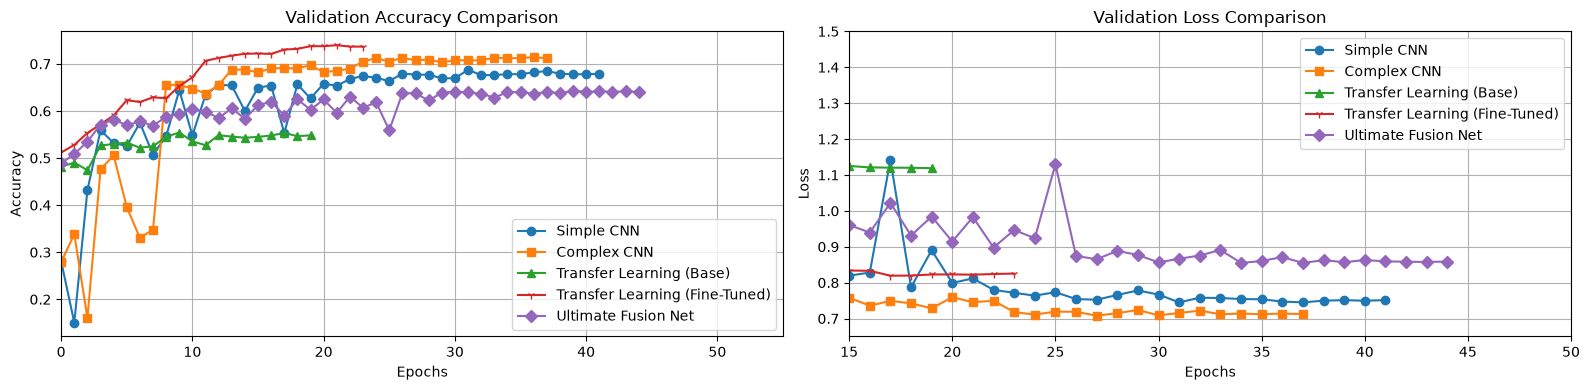

In [24]:
# Setup plotting comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

# Accuracy comparison
ax1.plot(history_simple.history['val_accuracy'], label='Simple CNN', marker='o')
ax1.plot(history_complex.history['val_accuracy'], label='Complex CNN', marker='s')
ax1.plot(history_transfer.history['val_accuracy'], label='Transfer Learning (Base)', marker='^')
ax1.plot(history_transfer_finetune.history['val_accuracy'], label='Transfer Learning (Fine-Tuned)', marker='1')
ax1.plot(history_ultimate.history['val_accuracy'], label='Ultimate Fusion Net', marker='D')

ax1.set_title('Validation Accuracy Comparison')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_xlim(0, 55)
ax1.legend()
ax1.grid(True)

# Loss comparison
ax2.plot(history_simple.history['val_loss'], label='Simple CNN', marker='o')
ax2.plot(history_complex.history['val_loss'], label='Complex CNN', marker='s')
ax2.plot(history_transfer.history['val_loss'], label='Transfer Learning (Base)', marker='^')
ax2.plot(history_transfer_finetune.history['val_loss'], label='Transfer Learning (Fine-Tuned)', marker='1')
ax2.plot(history_ultimate.history['val_loss'], label='Ultimate Fusion Net', marker='D')

ax2.set_title('Validation Loss Comparison')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.set_xlim(15, 50)
ax2.set_ylim(.65, 1.5)
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()